# Notebook 03 · Evaluasi dan Analisis

| | |
|---|---|
| Nama | Dimas Fadilah Permana R |
| NIM | 25.55.1752 |
| Program Studi | S2 PJJ Informatika, Universitas AMIKOM Yogyakarta |
| Pembimbing | Prof. Dr. Ema Utami, S.Si., M.Kom. |

Notebook ini hanya membaca prediksi yang sudah disimpan notebook 02, jadi seluruh isinya bisa
dijalankan ulang dalam beberapa menit tanpa melatih model lagi. Setiap tabel dan gambar disimpan
ke folder `tabel_paper/` dan dipakai di paper.

---
# Persiapan
### Deteksi lingkungan dan lokasi data
**Dua input** dari keluaran notebook 01 dan keluaran
notebook 02.

In [1]:
import os

# Kaggle juga memasang paket google.colab, jadi Colab dikenali dari penanda khas Colab
DI_KAGGLE = os.path.exists('/kaggle/input') or 'KAGGLE_KERNEL_RUN_TYPE' in os.environ
IN_COLAB = (not DI_KAGGLE) and (os.path.exists('/var/colab/hostname') or 'COLAB_RELEASE_TAG' in os.environ)
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

if DI_KAGGLE:
    CARI_DI, OUT_BASE = '/kaggle/input', '/kaggle/working'
elif IN_COLAB:
    CARI_DI = OUT_BASE = '/content/drive/MyDrive/Tesis_Dimas/dataset_tsinghua'
else:
    CARI_DI = OUT_BASE = os.environ.get('TESIS_OUT_BASE', './hasil')

import fnmatch

def cari_berkas(akar, pola):
    # telusuri semua subfolder (termasuk symlink), kembalikan berkas pertama yang cocok dengan pola
    for folder, subfolder, berkas in os.walk(akar, followlinks=True):
        subfolder.sort()
        for nama in sorted(berkas):
            if fnmatch.fnmatch(nama, pola):
                return os.path.join(folder, nama)
    return None

def cari_folder(akar, nama_folder, isi=None):
    # folder bernama nama_folder (dan berisi 'isi', bila diberikan)
    for folder, subfolder, berkas in os.walk(akar, followlinks=True):
        subfolder.sort()
        if os.path.basename(folder) == nama_folder and (isi is None or isi in subfolder + berkas):
            return folder
    return None

def tampilkan_isi(akar, kedalaman=3):
    # dipakai bila ada berkas yang tidak ditemukan, untuk melihat struktur folder input
    print(f"Isi {akar}:")
    for folder, subfolder, berkas in os.walk(akar, followlinks=True):
        tingkat = folder[len(akar):].count(os.sep)
        print('   ' * tingkat + (os.path.basename(folder) or akar) + f'/  ({len(berkas)} berkas)')
        if tingkat >= kedalaman - 1:
            subfolder[:] = []
        for b in sorted(berkas)[:4]:
            print('   ' * (tingkat + 1) + b)

DATA_DIR = cari_folder(CARI_DI, 'final_revisi', 'dataset_full.csv')
DATA_DIR_AUTHOR = cari_folder(CARI_DI, 'final_revisi_authorsplit', 'dataset_full.csv')
HASIL_DIR = cari_folder(CARI_DI, 'hasil_model_revisi', 'utama')
if not (DATA_DIR and DATA_DIR_AUTHOR and HASIL_DIR):
    tampilkan_isi(CARI_DI)
    raise FileNotFoundError("Keluaran notebook 01 dan 02 belum ditemukan (Add Input > Your Work).")
TABEL_DIR = os.path.join(OUT_BASE, 'tabel_paper')
os.makedirs(TABEL_DIR, exist_ok=True)

print(f"Lingkungan : {'Kaggle' if DI_KAGGLE else 'Colab' if IN_COLAB else 'Lokal'}")
print(f"Data       : {DATA_DIR}")
print(f"Prediksi   : {HASIL_DIR}")
print(f"Tabel paper: {TABEL_DIR}")

Lingkungan : Kaggle
Data       : /kaggle/input/notebooks/dimasfadilahamikom/notebook-01-preprocessing/final_revisi
Prediksi   : /kaggle/input/notebooks/dimasfadilahamikom/02-modeling/hasil_model_revisi
Tabel paper: /kaggle/working/tabel_paper


### Impor pustaka (library) dan pengaturan

In [2]:
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr, rankdata

warnings.filterwarnings('ignore')
pd.set_option('display.max_colwidth', 80)
plt.rcParams['figure.dpi'] = 110
sns.set_style('whitegrid')

SEED = 42
B = 2000            # jumlah ulangan bootstrap
ALPHA = 0.05

# Nama tampilan dan jalur input setiap model
NAMA = {
    'durasi_xgb': 'XGBoost (durasi saja)',
    'tfidf_rf_teks': 'TF-IDF + RF', 'tfidf_xgb_teks': 'TF-IDF + XGBoost',
    'bilstm_teks': 'Bi-LSTM', 'bert_teks': 'BERT',
    'tfidf_rf_gab': 'TF-IDF + RF', 'tfidf_xgb_gab': 'TF-IDF + XGBoost',
    'bilstm_gab': 'Bi-LSTM', 'bert_gab': 'BERT',
    'bert_gab_proyeksi': 'BERT (durasi diproyeksikan)', 'bert_gab_token': 'BERT (durasi sebagai teks)',
}
def jalur(kode):
    if kode == 'durasi_xgb':
        return 'durasi'
    if kode in ('bert_gab_proyeksi', 'bert_gab_token'):
        return 'ablation'
    return 'teks' if kode.endswith('_teks') else 'teks + durasi'
URUT_JALUR = ['durasi', 'teks', 'teks + durasi', 'ablation']
WARNA = {'durasi': '#7F7F7F', 'teks': '#2E75B6', 'teks + durasi': '#1F4E79', 'ablation': '#C55A11'}
print("Siap.")

Siap.


---
# TAHAP 1 · Metrik Evaluasi

Notasi: $y_i$ retensi aktual video ke-$i$, $\hat{y}_i$ prediksi, $n$ jumlah video uji, $d_i$ durasi.

| Metrik | Rumus | Arti |
|---|---|---|
| MAE | $\frac{1}{n}\sum_i \lvert y_i - \hat{y}_i \rvert$ | Rata-rata selisih prediksi dengan nilai aktual, dalam satuan retensi |
| RMSE | $\sqrt{\frac{1}{n}\sum_i (y_i - \hat{y}_i)^2}$ | Seperti MAE, tetapi galat besar dihukum lebih berat |
| SRC (metrik utama) | $\rho = 1 - \frac{6\sum_i (r_i - s_i)^2}{n(n^2 - 1)}$ | Korelasi peringkat Spearman; $r_i$ dan $s_i$ adalah peringkat $y_i$ dan $\hat{y}_i$. Mengukur seberapa benar model **mengurutkan** video |
| SRC parsial | $\rho_{y\hat{y}\cdot d} = \mathrm{corr}\left(e_{r}, e_{s}\right)$ | $e_r$ dan $e_s$ adalah sisa regresi linear peringkat $y$ dan peringkat $\hat{y}$ terhadap peringkat durasi. Mengukur kemampuan mengurutkan **di luar** informasi durasi |
| Lift desil | $\bar{y}_{\text{desil prediksi teratas}} \,/\, \bar{y}_{\text{desil prediksi terbawah}}$ | Berapa kali lipat retensi video yang diprediksi paling tinggi dibanding yang diprediksi paling rendah |
| Precision@10% | $\frac{1}{k}\sum_{i \in \text{Top}_{10\%}(\hat{y})} \mathbb{1}\left[y_i \geq Q_{0,7}(y)\right]$ | Dari 10% video yang diprediksi paling tinggi ($k$ video), berapa persen yang benar-benar termasuk 30% retensi teratas. Tebakan acak menghasilkan 30% |

SRC dipakai sebagai metrik utama karena kegunaan praktis model ini adalah **mengurutkan** naskah
dari yang paling berpotensi ditonton tuntas, bukan menebak angka retensi persisnya.

**Ketidakpastian.** Setiap metrik dilengkapi selang kepercayaan 95% dari *bootstrap* (2.000 kali
mengambil ulang video uji secara acak dengan pengembalian). Untuk membandingkan dua model,
selisih SRC dihitung pada sampel bootstrap yang sama (berpasangan). Nilai p dua arah adalah
$p = 2\min\left(P(\Delta \le 0), P(\Delta \ge 0)\right)$, lalu dikoreksi dengan metode Holm karena
banyak pasangan diuji sekaligus.

In [3]:
def mae(y, p):  return float(np.mean(np.abs(y - p)))
def rmse(y, p): return float(np.sqrt(np.mean((y - p) ** 2)))
def src(y, p):  return float(spearmanr(y, p)[0])

def src_parsial(y, p, d):
    ry, rp, rd = rankdata(y), rankdata(p), rankdata(d)
    sisa = lambda r: r - np.polyval(np.polyfit(rd, r, 1), rd)
    return float(np.corrcoef(sisa(ry), sisa(rp))[0, 1])

def lift_desil(y, p):
    urut = np.argsort(p)
    desil = np.array_split(urut, 10)
    bawah = y[desil[0]].mean()
    return float(y[desil[-1]].mean() / bawah) if bawah > 0 else np.nan   # tak bermakna bila target bisa negatif

def presisi_10(y, p):
    k = int(round(0.10 * len(y)))
    teratas = np.argsort(-p)[:k]
    return float((y[teratas] >= np.quantile(y, 0.70)).mean())

def holm(p):
    p = np.asarray(p, float); m = len(p); urut = np.argsort(p)
    hasil = np.empty(m); berjalan = 0.0
    for i, j in enumerate(urut):
        berjalan = max(berjalan, min(1.0, (m - i) * p[j]))
        hasil[j] = berjalan
    return hasil

print("Fungsi metrik siap.")

Fungsi metrik siap.


---
# TAHAP 2 · Memuat Hasil dan Hyperparameter Terpilih

### 2.1 Memuat prediksi semua eksperimen
Prediksi data uji dari notebook 02 digabung dengan atribut video uji dari notebook 01 (durasi, panjang
transkrip, jumlah penonton). Indeks bootstrap dibuat sekali per eksperimen, sehingga semua model
dinilai pada sampel ulang yang sama.

In [4]:
data_lengkap = {'random': pd.read_csv(f'{DATA_DIR}/dataset_full.csv'),
                'author': pd.read_csv(f'{DATA_DIR_AUTHOR}/dataset_full.csv')}
SPLIT = {'utama': 'random', 'adj': 'random', 'author': 'author', 'noclip': 'random'}

HASIL = {}
for kode in ['utama', 'adj', 'author', 'noclip']:
    folder = f'{HASIL_DIR}/{kode}'
    if not os.path.exists(f'{folder}/prediksi_uji.csv'):
        print(f"[{kode}] belum ada, dilewati"); continue
    pred = pd.read_csv(f'{folder}/prediksi_uji.csv')
    uji = data_lengkap[SPLIT[kode]].query("split == 'test'")
    pred = pred.merge(uji.drop(columns=['split']), on='pid', how='left')
    model = [c for c in pred.columns if c in NAMA]
    rng = np.random.default_rng(SEED)
    HASIL[kode] = {'df': pred, 'model': model, 'log': pd.read_csv(f'{folder}/log_tuning.csv'),
                   'idx': rng.integers(0, len(pred), size=(B, len(pred)))}
    print(f"[{kode:6s}] {len(pred):,} video uji | {len(model)} model: {model}")

[utama ] 698 video uji | 11 model: ['durasi_xgb', 'tfidf_rf_teks', 'tfidf_rf_gab', 'tfidf_xgb_teks', 'tfidf_xgb_gab', 'bilstm_teks', 'bilstm_gab', 'bert_teks', 'bert_gab', 'bert_gab_proyeksi', 'bert_gab_token']
[adj   ] 698 video uji | 9 model: ['durasi_xgb', 'tfidf_rf_teks', 'tfidf_rf_gab', 'tfidf_xgb_teks', 'tfidf_xgb_gab', 'bilstm_teks', 'bilstm_gab', 'bert_teks', 'bert_gab']
[author] 704 video uji | 9 model: ['durasi_xgb', 'tfidf_rf_teks', 'tfidf_rf_gab', 'tfidf_xgb_teks', 'tfidf_xgb_gab', 'bilstm_teks', 'bilstm_gab', 'bert_teks', 'bert_gab']
[noclip] 698 video uji | 5 model: ['durasi_xgb', 'tfidf_rf_teks', 'tfidf_rf_gab', 'tfidf_xgb_teks', 'tfidf_xgb_gab']


### 2.2 Pencarian dan hyperparameter terpilih

Ruang pencarian yang dipakai di notebook 02:

| Model | Hiperparameter yang dicari | Nilai tetap |
|---|---|---|
| XGBoost (durasi saja) | `max_depth` {2, 3, 4}, `learning_rate` {0,05; 0,1} | subsample 0,9; jumlah pohon lewat early stopping (maks. 1.000) |
| TF-IDF + RF | `max_features` {sqrt, 0,1}, `min_samples_leaf` {1, 5} | 200 pohon; TF-IDF 5.000 istilah, unigram dan bigram |
| TF-IDF + XGBoost | `max_depth` {3, 6}, `learning_rate` {0,05; 0,1} | subsample 0,9; colsample 0,9; early stopping (maks. 1.000) |
| Bi-LSTM | learning rate {1e-3, 3e-3, 5e-3} | embedding 100, 128 unit per arah, dropout 0,3 |
| BERT | learning rate {1e-5, 3e-5, 5e-5} | bert-base-uncased, token [CLS], dropout 0,3 |
| Semua deep learning | | AdamW, loss MSE, maks. 8 epoch, batch 32, early stopping 2 epoch, 128 token |

Kriteria pemilihan untuk semua model: RMSE terendah pada data validasi.

In [5]:
log = HASIL['utama']['log']
tabel_hp = (log.groupby('model')
               .apply(lambda g: pd.Series({
                   'Kombinasi dicoba': len(g),
                   'Parameter terpilih': g.loc[g['terpilih'], 'parameter'].iloc[0],
                   'RMSE validasi': round(g.loc[g['terpilih'], 'rmse_val'].iloc[0], 4)}))
               .reindex(HASIL['utama']['model']).reset_index())
tabel_hp.insert(1, 'Jalur', tabel_hp['model'].map(jalur))
tabel_hp['model'] = tabel_hp['model'].map(NAMA)
tabel_hp.to_csv(f'{TABEL_DIR}/hiperparameter_terpilih.csv', index=False)
display(tabel_hp)

,model,Jalur,Kombinasi dicoba,Parameter terpilih,RMSE validasi
0,XGBoost (durasi saja),durasi,6,"learning_rate=0.05, max_depth=2, n_pohon=45",0.1924
1,TF-IDF + RF,teks,4,"max_features=0.1, min_samples_leaf=5",0.2030
2,TF-IDF + RF,teks + durasi,4,"max_features=0.1, min_samples_leaf=1",0.1884
3,TF-IDF + XGBoost,teks,4,"learning_rate=0.05, max_depth=3, n_pohon=138",0.2023
4,TF-IDF + XGBoost,teks + durasi,4,"learning_rate=0.05, max_depth=3, n_pohon=165",0.1888
5,Bi-LSTM,teks,3,"lr=0.005, epoch=3",0.2244
6,Bi-LSTM,teks + durasi,3,"lr=0.003, epoch=3",0.2126
7,BERT,teks,3,"lr=1e-05, epoch=5",0.2017
8,BERT,teks + durasi,3,"lr=5e-05, epoch=5",0.2006
9,BERT (durasi diproyeksikan),ablation,3,"lr=1e-05, epoch=5",0.2025


---
# TAHAP 3 · Hasil Utama

Eksperimen utama: partisi acak, target `retensi`. Model dikelompokkan menurut jalur input, dan
perbandingan yang adil hanya di dalam jalur yang sama.

In [6]:
def tabel_kinerja(kode):
    H = HASIL[kode]; d = H['df']; y = d['y_true'].values; dur = d['duration'].values
    H['boot_src'] = {}
    baris = []
    for m in H['model']:
        p = d[m].values
        with np.errstate(invalid='ignore'):
            boot = np.array([src(y[i], p[i]) for i in H['idx']])
        H['boot_src'][m] = boot
        gagal = np.isnan(boot).sum()
        if gagal:
            # SRC tidak terdefinisi bila semua prediksi di satu sampel ulang bernilai sama
            print(f"[{kode}] {NAMA[m]} [{jalur(m)}]: {gagal} dari {B} sampel bootstrap tanpa variasi prediksi "
                  f"(SD prediksi {p.std():.4f}, nilai unik {len(np.unique(p))})")
        baris.append({'kode': m, 'Jalur': jalur(m), 'Model': NAMA[m],
                      'SRC': src(y, p), 'IK95% bawah': np.nanpercentile(boot, 2.5),
                      'IK95% atas': np.nanpercentile(boot, 97.5),
                      'SRC parsial': src_parsial(y, p, dur),
                      'MAE': mae(y, p), 'RMSE': rmse(y, p),
                      # target adj berpusat di nol, sehingga rasio desil tidak bermakna
                      'Lift desil': np.nan if kode == 'adj' else lift_desil(y, p),
                      'Precision@10%': presisi_10(y, p),
                      'SD prediksi': p.std()})
    t = pd.DataFrame(baris)
    t['Jalur'] = pd.Categorical(t['Jalur'], URUT_JALUR, ordered=True)
    return t.sort_values(['Jalur', 'SRC'], ascending=[True, False]).reset_index(drop=True)

hasil_utama = tabel_kinerja('utama')
hasil_utama.drop(columns='kode').round(3).to_csv(f'{TABEL_DIR}/hasil_utama.csv', index=False)
display(hasil_utama.drop(columns='kode').round(3))

,Jalur,Model,SRC,IK95% bawah,IK95% atas,SRC parsial,MAE,RMSE,Lift desil,Precision@10%,SD prediksi
0,durasi,XGBoost (durasi saja),0.476,0.415,0.534,-0.028,0.148,0.183,1.811,0.700,0.097
1,teks,TF-IDF + RF,0.299,0.230,0.363,0.008,0.164,0.200,1.431,0.429,0.074
2,teks,TF-IDF + XGBoost,0.277,0.207,0.343,-0.001,0.165,0.201,1.361,0.400,0.075
3,teks,BERT,0.272,0.199,0.343,-0.001,0.165,0.204,1.415,0.429,0.084
4,teks,Bi-LSTM,0.100,0.027,0.174,0.010,0.177,0.217,1.145,0.400,0.076
5,teks + durasi,TF-IDF + XGBoost,0.483,0.418,0.538,0.112,0.147,0.182,1.808,0.686,0.107
6,teks + durasi,TF-IDF + RF,0.461,0.398,0.516,0.074,0.151,0.187,1.735,0.629,0.106
7,teks + durasi,BERT,0.319,0.245,0.390,0.036,0.161,0.201,1.328,0.429,0.093
8,teks + durasi,Bi-LSTM,0.255,0.182,0.326,-0.004,0.166,0.204,1.341,0.471,0.080
9,ablation,BERT (durasi sebagai teks),0.470,0.406,0.528,0.081,0.150,0.186,1.805,0.643,0.120


### 3.1 Grafik SRC per model dengan selang kepercayaan 95%

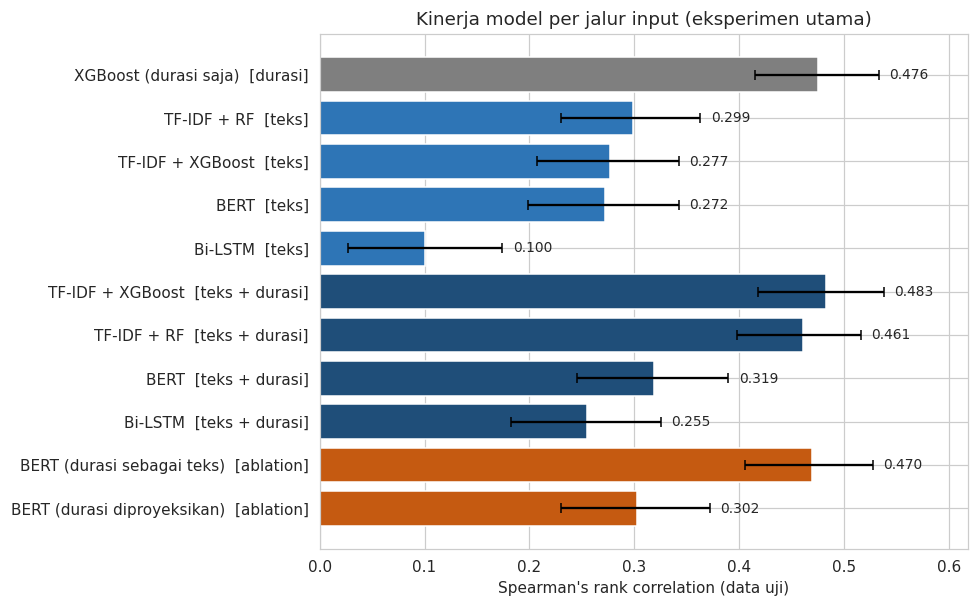

In [7]:
t = hasil_utama.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 0.42 * len(t) + 1))
label = [f"{r['Model']}  [{r['Jalur']}]" for _, r in t.iterrows()]
ax.barh(label, t['SRC'], color=[WARNA[j] for j in t['Jalur']],
        xerr=[t['SRC'] - t['IK95% bawah'], t['IK95% atas'] - t['SRC']], capsize=3)
for i, (v, atas) in enumerate(zip(t['SRC'], t['IK95% atas'])):
    ax.text(atas + 0.01, i, f'{v:.3f}', va='center', fontsize=9)
ax.set_xlim(right=t['IK95% atas'].max() + 0.08)
ax.set_xlabel("Spearman's rank correlation (data uji)")
ax.set_title('Kinerja model per jalur input (eksperimen utama)')
plt.tight_layout(); plt.savefig(f'{TABEL_DIR}/gambar_src_utama.png', dpi=200, bbox_inches='tight'); plt.show()

---
# TAHAP 4 · Uji Beda Berpasangan

Setiap pasangan menjawab satu pertanyaan spesifik. Selisih positif berarti model A lebih baik.

| Kelompok | Pertanyaan |
|---|---|
| Teks saja | Representasi teks mana yang paling baik bila model hanya membaca transkrip? |
| Teks + durasi | Arsitektur mana yang paling baik bila durasi juga tersedia? |
| Teks di atas durasi | Apakah menambahkan teks memperbaiki model yang hanya memakai durasi? |
| Efek durasi | Apakah menambahkan durasi memperbaiki tiap arsitektur? (faktorial 2×2) |

Selain selisih SRC, ditampilkan juga selisih precision@10% sebagai ukuran manfaat praktis.

In [8]:
PASANGAN = [
    ('Teks saja', 'bert_teks', 'tfidf_xgb_teks'), ('Teks saja', 'bert_teks', 'tfidf_rf_teks'),
    ('Teks saja', 'bert_teks', 'bilstm_teks'), ('Teks saja', 'tfidf_xgb_teks', 'bilstm_teks'),
    ('Teks + durasi', 'tfidf_xgb_gab', 'bert_gab'), ('Teks + durasi', 'tfidf_xgb_gab', 'bilstm_gab'),
    ('Teks + durasi', 'bert_gab', 'bilstm_gab'),
    ('Teks di atas durasi', 'tfidf_xgb_gab', 'durasi_xgb'), ('Teks di atas durasi', 'tfidf_rf_gab', 'durasi_xgb'),
    ('Teks di atas durasi', 'bilstm_gab', 'durasi_xgb'), ('Teks di atas durasi', 'bert_gab', 'durasi_xgb'),
    ('Efek durasi', 'tfidf_xgb_gab', 'tfidf_xgb_teks'), ('Efek durasi', 'tfidf_rf_gab', 'tfidf_rf_teks'),
    ('Efek durasi', 'bilstm_gab', 'bilstm_teks'), ('Efek durasi', 'bert_gab', 'bert_teks'),
]

def uji_pasangan(kode, pasangan):
    H = HASIL[kode]; d = H['df']; y = d['y_true'].values
    baris = []
    for grup, a, b in pasangan:
        if a not in H['model'] or b not in H['model']:
            continue
        delta = H['boot_src'][a] - H['boot_src'][b]
        delta = delta[~np.isnan(delta)]
        p = max(2 * min((delta <= 0).mean(), (delta >= 0).mean()), 1 / len(delta))
        baris.append({'kode A': a, 'kode B': b, 'Kelompok': grup, 'Model A': f"{NAMA[a]} [{jalur(a)}]", 'Model B': f"{NAMA[b]} [{jalur(b)}]",
                      'Selisih SRC': src(y, d[a]) - src(y, d[b]),
                      'IK95% bawah': np.percentile(delta, 2.5), 'IK95% atas': np.percentile(delta, 97.5),
                      'p bootstrap': p,
                      'Selisih Precision@10%': presisi_10(y, d[a].values) - presisi_10(y, d[b].values)})
    t = pd.DataFrame(baris)
    t['p Holm'] = holm(t['p bootstrap'])
    t['Signifikan (Holm)'] = np.where(t['p Holm'] < ALPHA, 'ya', 'tidak')
    return t

uji_utama = uji_pasangan('utama', PASANGAN)
uji_utama.drop(columns=['kode A', 'kode B']).round(4).to_csv(f'{TABEL_DIR}/uji_berpasangan.csv', index=False)
display(uji_utama.drop(columns=['kode A', 'kode B']).round(4))
print("Catatan: kolom 'SD prediksi' di tabel kinerja dipakai untuk mendeteksi model yang prediksinya hampir datar.")

,Kelompok,Model A,Model B,Selisih SRC,IK95% bawah,IK95% atas,p bootstrap,Selisih Precision@10%,p Holm,Signifikan (Holm)
0,Teks saja,BERT [teks],TF-IDF + XGBoost [teks],-0.0051,-0.0534,0.0431,0.8270,0.0286,1.0000,tidak
1,Teks saja,BERT [teks],TF-IDF + RF [teks],-0.0268,-0.0715,0.0188,0.2300,0.0000,0.9200,tidak
2,Teks saja,BERT [teks],Bi-LSTM [teks],0.1713,0.0794,0.2662,0.0005,0.0286,0.0075,ya
3,Teks saja,TF-IDF + XGBoost [teks],Bi-LSTM [teks],0.1764,0.0902,0.2607,0.0005,0.0000,0.0075,ya
4,Teks + durasi,TF-IDF + XGBoost [teks + durasi],BERT [teks + durasi],0.1636,0.1039,0.2247,0.0005,0.2571,0.0075,ya
5,Teks + durasi,TF-IDF + XGBoost [teks + durasi],Bi-LSTM [teks + durasi],0.2278,0.1633,0.2939,0.0005,0.2143,0.0075,ya
6,Teks + durasi,BERT [teks + durasi],Bi-LSTM [teks + durasi],0.0643,-0.0146,0.1443,0.1030,-0.0429,0.5150,tidak
7,Teks di atas durasi,TF-IDF + XGBoost [teks + durasi],XGBoost (durasi saja) [durasi],0.0071,-0.0211,0.0349,0.6270,-0.0143,1.0000,tidak
8,Teks di atas durasi,TF-IDF + RF [teks + durasi],XGBoost (durasi saja) [durasi],-0.0143,-0.0471,0.0179,0.3880,-0.0714,1.0000,tidak
9,Teks di atas durasi,Bi-LSTM [teks + durasi],XGBoost (durasi saja) [durasi],-0.2207,-0.2886,-0.1547,0.0005,-0.2286,0.0075,ya


Catatan: kolom 'SD prediksi' di tabel kinerja dipakai untuk mendeteksi model yang prediksinya hampir datar.


---
# TAHAP 5 · Peran Durasi

### 5.1 Keterkaitan matematis durasi dengan target

Retensi dihitung dengan membagi waktu tonton dengan durasi. Karena itu, sebagian hubungan negatif
antara durasi dan retensi muncul dari rumusnya sendiri. Untuk mengukurnya, waktu tonton rata-rata
(dalam detik) diacak antar-video sebanyak 1.000 kali, sehingga waktu tonton sama sekali tidak
bergantung pada durasi, lalu retensi dihitung ulang dengan rumus yang sama. Korelasi pada kondisi
acak ini adalah korelasi yang muncul **hanya karena rumus**.

Karena $r_{ij} = \min(w_{ij}, d_i)/d_i$, retensi video sama dengan `detik_tonton` dibagi durasi.

,Ukuran,Nilai
0,"SRC(durasi, retensi) pada data",-0.484
1,"SRC(durasi, retensi) bila waktu tonton acak (rata-rata)",-0.719
2,batas bawah IK95% kondisi acak,-0.727
3,batas atas IK95% kondisi acak,-0.708
4,"SRC(durasi, detik yang ditonton) pada data",0.819
5,"SRC(durasi, retensi_adj) pada data",0.012


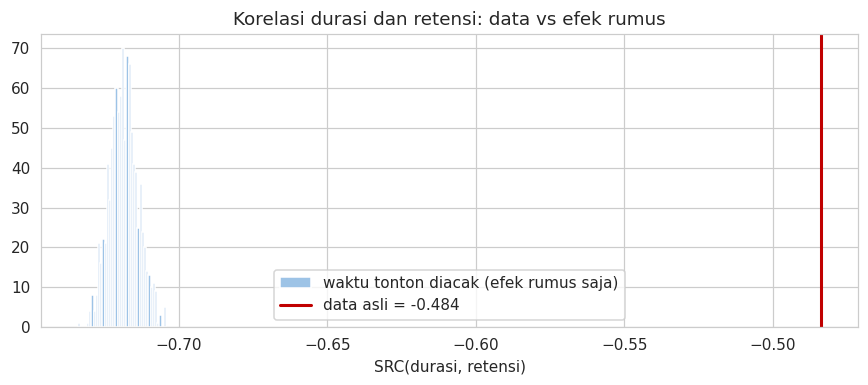

In [9]:
full = data_lengkap['random']
D, W, R = full['duration'].values, full['detik_tonton'].values, full['retensi'].values
assert np.allclose(R, W / D, atol=1e-6), "retensi seharusnya sama dengan detik_tonton / durasi"

rng = np.random.default_rng(SEED)
nol = np.array([src(D, np.minimum(rng.permutation(W), D) / D) for _ in range(1000)])
kopling = pd.DataFrame([
    {'Ukuran': 'SRC(durasi, retensi) pada data', 'Nilai': src(D, R)},
    {'Ukuran': 'SRC(durasi, retensi) bila waktu tonton acak (rata-rata)', 'Nilai': nol.mean()},
    {'Ukuran': '  batas bawah IK95% kondisi acak', 'Nilai': np.percentile(nol, 2.5)},
    {'Ukuran': '  batas atas IK95% kondisi acak', 'Nilai': np.percentile(nol, 97.5)},
    {'Ukuran': 'SRC(durasi, detik yang ditonton) pada data', 'Nilai': src(D, W)},
    {'Ukuran': 'SRC(durasi, retensi_adj) pada data', 'Nilai': src(D, full['retensi_adj'].values)},
])
kopling.round(3).to_csv(f'{TABEL_DIR}/kopling_durasi_target.csv', index=False)
display(kopling.round(3))

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(nol, bins=40, color='#9DC3E6', edgecolor='white', label='waktu tonton diacak (efek rumus saja)')
ax.axvline(src(D, R), color='#C00000', lw=2, label=f'data asli = {src(D, R):.3f}')
ax.set_xlabel('SRC(durasi, retensi)'); ax.legend(); ax.set_title('Korelasi durasi dan retensi: data vs efek rumus')
plt.tight_layout(); plt.savefig(f'{TABEL_DIR}/gambar_kopling.png', dpi=200, bbox_inches='tight'); plt.show()

### 5.2 Faktorial 2×2 (arsitektur × durasi)
Tabel ini menunjukkan seberapa besar penambahan durasi mengubah SRC untuk setiap arsitektur.
Selang kepercayaan (CI/Confidence Interval) selisih diambil dari bootstrap berpasangan.

,Arsitektur,SRC teks saja,SRC teks + durasi,Efek durasi,IK95% bawah,IK95% atas
0,TF-IDF + RF,0.299,0.461,0.163,0.114,0.214
1,TF-IDF + XGBoost,0.277,0.483,0.206,0.152,0.263
2,Bi-LSTM,0.100,0.255,0.155,0.103,0.209
3,BERT,0.272,0.319,0.048,0.012,0.082


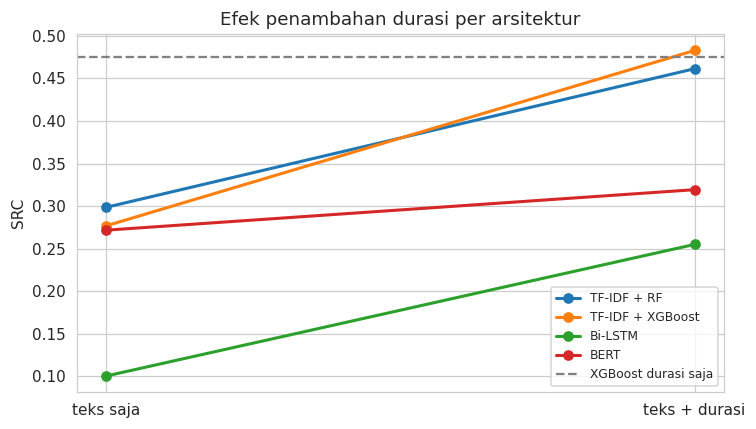

In [10]:
H = HASIL['utama']; y = H['df']['y_true'].values
faktorial = []
for arsitektur, teks, gab in [('TF-IDF + RF', 'tfidf_rf_teks', 'tfidf_rf_gab'),
                              ('TF-IDF + XGBoost', 'tfidf_xgb_teks', 'tfidf_xgb_gab'),
                              ('Bi-LSTM', 'bilstm_teks', 'bilstm_gab'), ('BERT', 'bert_teks', 'bert_gab')]:
    delta = H['boot_src'][gab] - H['boot_src'][teks]
    faktorial.append({'Arsitektur': arsitektur, 'SRC teks saja': src(y, H['df'][teks]),
                      'SRC teks + durasi': src(y, H['df'][gab]),
                      'Efek durasi': src(y, H['df'][gab]) - src(y, H['df'][teks]),
                      'IK95% bawah': np.nanpercentile(delta, 2.5), 'IK95% atas': np.nanpercentile(delta, 97.5)})
faktorial = pd.DataFrame(faktorial)
faktorial.round(3).to_csv(f'{TABEL_DIR}/faktorial_2x2.csv', index=False)
display(faktorial.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
for _, r in faktorial.iterrows():
    ax.plot(['teks saja', 'teks + durasi'], [r['SRC teks saja'], r['SRC teks + durasi']], marker='o', lw=2,
            label=r['Arsitektur'])
ax.axhline(src(y, H['df']['durasi_xgb']), color='gray', ls='--', label='XGBoost durasi saja')
ax.set_ylabel('SRC'); ax.set_title('Efek penambahan durasi per arsitektur'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{TABEL_DIR}/gambar_faktorial.png', dpi=200, bbox_inches='tight'); plt.show()

### 5.3 Ablation Analysis: cara memasukkan durasi ke BERT
Bila BERT hanya gagal memakai durasi karena satu angka "tenggelam" di antara 768 angka `[CLS]`, maka
memproyeksikan durasi ke 32 dimensi atau menuliskannya sebagai teks seharusnya membantu.

In [11]:
ablasi = []
for m in ['bert_teks', 'bert_gab', 'bert_gab_proyeksi', 'bert_gab_token']:
    if m not in H['model']:
        continue
    delta = H['boot_src'][m] - H['boot_src']['bert_teks']
    label = {'bert_teks': 'BERT (teks saja, pembanding)', 'bert_gab': 'BERT (durasi late fusion)'}.get(m, NAMA[m])
    ablasi.append({'Varian': label,
                   'SRC': src(y, H['df'][m]), 'Selisih vs BERT teks saja': src(y, H['df'][m]) - src(y, H['df']['bert_teks']),
                   'IK95% bawah': np.nanpercentile(delta, 2.5), 'IK95% atas': np.nanpercentile(delta, 97.5)})
ablasi = pd.DataFrame(ablasi)
ablasi.loc[0, ['Selisih vs BERT teks saja', 'IK95% bawah', 'IK95% atas']] = np.nan
ablasi.round(3).to_csv(f'{TABEL_DIR}/ablation_durasi_bert.csv', index=False)
display(ablasi.round(3))

,Varian,SRC,Selisih vs BERT teks saja,IK95% bawah,IK95% atas
0,"BERT (teks saja, pembanding)",0.272,NaN,NaN,NaN
1,BERT (durasi late fusion),0.319,0.048,0.012,0.082
2,BERT (durasi diproyeksikan),0.302,0.031,-0.008,0.067
3,BERT (durasi sebagai teks),0.470,0.198,0.140,0.258


---
# TAHAP 6 · Target Pembanding dan Uji Ketahanan

### 6.1 Target yang dikontrol durasi (`retensi_adj`)
Pada target ini efek durasi sudah dikeluarkan, sehingga model durasi saja seharusnya mendekati nol.
SRC di atas nol pada model teks menunjukkan informasi dari transkrip yang tidak berasal dari durasi.

In [12]:
if 'adj' in HASIL:
    hasil_adj = tabel_kinerja('adj')
    hasil_adj.drop(columns='kode').round(3).to_csv(f'{TABEL_DIR}/hasil_retensi_adj.csv', index=False)
    display(hasil_adj[['Jalur', 'Model', 'SRC', 'IK95% bawah', 'IK95% atas', 'MAE', 'SD prediksi']].round(3))

[adj] Bi-LSTM [teks]: 15 dari 2000 sampel bootstrap tanpa variasi prediksi (SD prediksi 0.0007, nilai unik 5)


,Jalur,Model,SRC,IK95% bawah,IK95% atas,MAE,SD prediksi
0,durasi,XGBoost (durasi saja),0.014,-0.060,0.085,0.148,0.011
1,teks,BERT,0.182,0.103,0.254,0.144,0.044
2,teks,TF-IDF + XGBoost,0.110,0.037,0.185,0.146,0.029
3,teks,TF-IDF + RF,0.092,0.018,0.163,0.146,0.041
4,teks,Bi-LSTM,0.064,0.017,0.103,0.147,0.001
5,teks + durasi,BERT,0.153,0.079,0.227,0.146,0.056
6,teks + durasi,TF-IDF + RF,0.098,0.027,0.170,0.146,0.040
7,teks + durasi,TF-IDF + XGBoost,0.084,0.007,0.161,0.146,0.033
8,teks + durasi,Bi-LSTM,0.054,-0.015,0.128,0.147,0.013


#### Uji beda berpasangan pada target `retensi_adj`
Pertanyaannya: setelah efek durasi dikeluarkan dari target, representasi teks mana yang menangkap
sinyal paling banyak, dan apakah model teks lebih baik daripada model durasi saja?

In [13]:
PASANGAN_ADJ = [
    ('Teks saja', 'bert_teks', 'tfidf_xgb_teks'), ('Teks saja', 'bert_teks', 'tfidf_rf_teks'),
    ('Teks saja', 'bert_teks', 'bilstm_teks'), ('Teks saja', 'tfidf_xgb_teks', 'bilstm_teks'),
    ('Teks vs durasi saja', 'bert_teks', 'durasi_xgb'), ('Teks vs durasi saja', 'tfidf_xgb_teks', 'durasi_xgb'),
    ('Teks vs durasi saja', 'tfidf_rf_teks', 'durasi_xgb'), ('Teks vs durasi saja', 'bilstm_teks', 'durasi_xgb'),
    ('Teks + durasi', 'bert_gab', 'tfidf_xgb_gab'), ('Teks + durasi', 'bert_gab', 'bilstm_gab'),
]
if 'adj' in HASIL:
    uji_adj = uji_pasangan('adj', PASANGAN_ADJ)
    uji_adj.drop(columns=['kode A', 'kode B']).round(4).to_csv(f'{TABEL_DIR}/uji_berpasangan_adj.csv', index=False)
    display(uji_adj.drop(columns=['kode A', 'kode B']).round(4))

,Kelompok,Model A,Model B,Selisih SRC,IK95% bawah,IK95% atas,p bootstrap,Selisih Precision@10%,p Holm,Signifikan (Holm)
0,Teks saja,BERT [teks],TF-IDF + XGBoost [teks],0.0726,-0.0144,0.1562,0.1120,0.0286,0.5100,tidak
1,Teks saja,BERT [teks],TF-IDF + RF [teks],0.0906,0.0181,0.1639,0.0110,0.0714,0.0880,tidak
2,Teks saja,BERT [teks],Bi-LSTM [teks],0.1187,0.0338,0.2028,0.0071,0.1143,0.0635,tidak
3,Teks saja,TF-IDF + XGBoost [teks],Bi-LSTM [teks],0.0460,-0.0345,0.1333,0.2640,0.0857,0.5100,tidak
4,Teks vs durasi saja,BERT [teks],XGBoost (durasi saja) [durasi],0.1680,0.0567,0.2698,0.0020,0.1429,0.0200,ya
5,Teks vs durasi saja,TF-IDF + XGBoost [teks],XGBoost (durasi saja) [durasi],0.0954,-0.0139,0.1978,0.0860,0.1143,0.5100,tidak
6,Teks vs durasi saja,TF-IDF + RF [teks],XGBoost (durasi saja) [durasi],0.0774,-0.0296,0.1766,0.1510,0.0714,0.5100,tidak
7,Teks vs durasi saja,Bi-LSTM [teks],XGBoost (durasi saja) [durasi],0.0494,-0.0329,0.1305,0.2539,0.0286,0.5100,tidak
8,Teks + durasi,BERT [teks + durasi],TF-IDF + XGBoost [teks + durasi],0.0697,-0.0108,0.1510,0.0850,0.0000,0.5100,tidak
9,Teks + durasi,BERT [teks + durasi],Bi-LSTM [teks + durasi],0.0998,0.0014,0.1965,0.0430,0.0000,0.3010,tidak


### 6.2 Sensitivitas terhadap pemotongan rasio dan efek plafon
Dua pemeriksaan: (1) model klasik dilatih ulang dengan target tanpa pemotongan rasio di atas 1,
(2) model eksperimen utama dinilai ulang tanpa video yang retensinya tepat 1 (plafon).

In [14]:
banding = hasil_utama[['kode', 'Jalur', 'Model', 'SRC']].rename(columns={'SRC': 'SRC utama'})
if 'noclip' in HASIL:
    hasil_noclip = tabel_kinerja('noclip')
    banding = banding.merge(hasil_noclip[['kode', 'SRC']].rename(columns={'SRC': 'SRC tanpa pemotongan'}),
                            on='kode', how='left')
d = HASIL['utama']['df']; bukan_plafon = d['y_true'] < 0.999
banding['SRC tanpa video plafon'] = [src(d.loc[bukan_plafon, 'y_true'], d.loc[bukan_plafon, m]) for m in banding['kode']]
print(f"Video uji dengan retensi = 1: {(~bukan_plafon).sum()} dari {len(d)}")
banding.drop(columns='kode').round(3).to_csv(f'{TABEL_DIR}/sensitivitas_target.csv', index=False)
display(banding.drop(columns='kode').round(3))

Video uji dengan retensi = 1: 9 dari 698


,Jalur,Model,SRC utama,SRC tanpa pemotongan,SRC tanpa video plafon
0,durasi,XGBoost (durasi saja),0.476,0.610,0.460
1,teks,TF-IDF + RF,0.299,0.382,0.292
2,teks,TF-IDF + XGBoost,0.277,0.365,0.268
3,teks,BERT,0.272,NaN,0.261
4,teks,Bi-LSTM,0.100,NaN,0.099
5,teks + durasi,TF-IDF + XGBoost,0.483,0.599,0.468
6,teks + durasi,TF-IDF + RF,0.461,0.560,0.448
7,teks + durasi,BERT,0.319,NaN,0.306
8,teks + durasi,Bi-LSTM,0.255,NaN,0.245
9,ablation,BERT (durasi sebagai teks),0.470,NaN,0.455


### 6.3 Partisi per kreator
Model dilatih ulang dengan partisi yang memisahkan kreator, sehingga tidak ada kreator di data uji
yang muncul di data latih. Penurunan kecil menandakan model tidak sekadar menghafal gaya kreator.

In [15]:
if 'author' in HASIL:
    hasil_author = tabel_kinerja('author')
    ketahanan = hasil_utama[['kode', 'Jalur', 'Model', 'SRC']].merge(
        hasil_author[['kode', 'SRC', 'IK95% bawah', 'IK95% atas']], on='kode', suffixes=(' acak', ' per kreator'))
    ketahanan['Selisih'] = ketahanan['SRC per kreator'] - ketahanan['SRC acak']
    ketahanan.drop(columns='kode').round(3).to_csv(f'{TABEL_DIR}/partisi_per_kreator.csv', index=False)
    display(ketahanan.drop(columns='kode').round(3))

    # pasangan yang sama dengan eksperimen utama, diuji ulang pada partisi per kreator
    uji_author = uji_pasangan('author', PASANGAN)
    uji_author.drop(columns=['kode A', 'kode B']).round(4).to_csv(f'{TABEL_DIR}/uji_berpasangan_author.csv', index=False)
    display(uji_author.drop(columns=['kode A', 'kode B']).round(4))

,Jalur,Model,SRC acak,SRC per kreator,IK95% bawah,IK95% atas,Selisih
0,durasi,XGBoost (durasi saja),0.476,0.528,0.475,0.581,0.052
1,teks,TF-IDF + RF,0.299,0.293,0.228,0.361,-0.006
2,teks,TF-IDF + XGBoost,0.277,0.297,0.233,0.363,0.020
3,teks,BERT,0.272,0.330,0.263,0.393,0.058
4,teks,Bi-LSTM,0.100,0.088,0.018,0.157,-0.012
5,teks + durasi,TF-IDF + XGBoost,0.483,0.528,0.473,0.582,0.045
6,teks + durasi,TF-IDF + RF,0.461,0.491,0.437,0.546,0.030
7,teks + durasi,BERT,0.319,0.361,0.297,0.424,0.042
8,teks + durasi,Bi-LSTM,0.255,0.354,0.285,0.419,0.099


,Kelompok,Model A,Model B,Selisih SRC,IK95% bawah,IK95% atas,p bootstrap,Selisih Precision@10%,p Holm,Signifikan (Holm)
0,Teks saja,BERT [teks],TF-IDF + XGBoost [teks],0.0330,-0.0072,0.0729,0.1190,0.0429,0.3570,tidak
1,Teks saja,BERT [teks],TF-IDF + RF [teks],0.0374,0.0010,0.0723,0.0440,0.0857,0.2200,tidak
2,Teks saja,BERT [teks],Bi-LSTM [teks],0.2417,0.1612,0.3253,0.0005,0.0714,0.0075,ya
3,Teks saja,TF-IDF + XGBoost [teks],Bi-LSTM [teks],0.2087,0.1291,0.2923,0.0005,0.0286,0.0075,ya
4,Teks + durasi,TF-IDF + XGBoost [teks + durasi],BERT [teks + durasi],0.1668,0.1139,0.2224,0.0005,0.2571,0.0075,ya
5,Teks + durasi,TF-IDF + XGBoost [teks + durasi],Bi-LSTM [teks + durasi],0.1738,0.1157,0.2358,0.0005,0.1571,0.0075,ya
6,Teks + durasi,BERT [teks + durasi],Bi-LSTM [teks + durasi],0.0070,-0.0616,0.0784,0.8220,-0.1000,1.0000,tidak
7,Teks di atas durasi,TF-IDF + XGBoost [teks + durasi],XGBoost (durasi saja) [durasi],-0.0003,-0.0315,0.0299,0.9570,0.0143,1.0000,tidak
8,Teks di atas durasi,TF-IDF + RF [teks + durasi],XGBoost (durasi saja) [durasi],-0.0370,-0.0692,-0.0034,0.0270,-0.0429,0.1620,tidak
9,Teks di atas durasi,Bi-LSTM [teks + durasi],XGBoost (durasi saja) [durasi],-0.1741,-0.2328,-0.1190,0.0005,-0.1429,0.0075,ya


---
# TAHAP 7 · Kinerja per Kelompok Video

### 7.1 Per panjang transkrip
Terkait video yang hampir tanpa ucapan. Video tanpa transkrip sudah dibuang di notebook
01, tetapi video dengan transkrip pendek tetap ada. Bila teks berguna, model teks seharusnya lebih
lemah pada transkrip pendek, sedangkan model durasi saja tidak terpengaruh.

,kelompok_panjang,n video,XGBoost (durasi saja) [durasi],TF-IDF + XGBoost [teks],BERT [teks],Bi-LSTM [teks],TF-IDF + XGBoost [teks + durasi],BERT [teks + durasi],Bi-LSTM [teks + durasi]
0,5-14 kata,154,0.549,0.070,-0.081,0.017,0.531,0.085,0.142
1,15-49 kata,187,0.529,0.145,0.204,0.066,0.499,0.291,0.227
2,50-127 kata,199,0.292,0.167,0.227,0.018,0.388,0.275,0.082
3,128 kata atau lebih,158,0.213,0.096,0.135,0.039,0.194,0.060,0.158


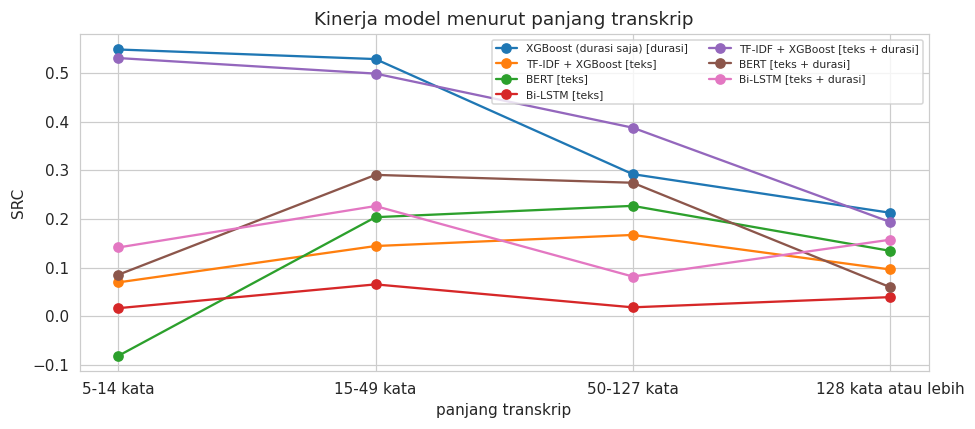

In [16]:
H = HASIL['utama']; d = H['df']
MODEL_KUNCI = ['durasi_xgb', 'tfidf_xgb_teks', 'bert_teks', 'bilstm_teks', 'tfidf_xgb_gab', 'bert_gab', 'bilstm_gab']
MODEL_KUNCI = [m for m in MODEL_KUNCI if m in H['model']]

def per_kelompok(kolom):
    baris = []
    for nilai, g in d.groupby(kolom, observed=True):
        r = {kolom: nilai, 'n video': len(g)}
        r.update({f"{NAMA[m]} [{jalur(m)}]": src(g['y_true'], g[m]) for m in MODEL_KUNCI})
        baris.append(r)
    return pd.DataFrame(baris)

URUT_PANJANG = ['5-14 kata', '15-49 kata', '50-127 kata', '128 kata atau lebih']
d['kelompok_panjang'] = pd.Categorical(d['kelompok_panjang'], URUT_PANJANG, ordered=True)
per_panjang = per_kelompok('kelompok_panjang')
per_panjang.round(3).to_csv(f'{TABEL_DIR}/kinerja_per_panjang_transkrip.csv', index=False)
display(per_panjang.round(3))

fig, ax = plt.subplots(figsize=(9, 4))
for kolom in per_panjang.columns[2:]:
    ax.plot(per_panjang['kelompok_panjang'].astype(str), per_panjang[kolom], marker='o', label=kolom)
ax.set_ylabel('SRC'); ax.set_xlabel('panjang transkrip'); ax.legend(fontsize=7, ncol=2)
ax.set_title('Kinerja model menurut panjang transkrip')
plt.tight_layout(); plt.savefig(f'{TABEL_DIR}/gambar_per_panjang.png', dpi=200, bbox_inches='tight'); plt.show()

### 7.2 Per jumlah penonton
Retensi yang dirata-rata dari lebih banyak penonton lebih andal. Bila SRC naik seiring jumlah
penonton, sebagian galat model berasal dari derau label, bukan dari modelnya.

In [17]:
d['kelompok_penonton'] = pd.cut(d['n_penonton'], [4, 9, 19, np.inf], labels=['5-9', '10-19', '20 atau lebih'])
per_penonton = per_kelompok('kelompok_penonton')
per_penonton.round(3).to_csv(f'{TABEL_DIR}/kinerja_per_jumlah_penonton.csv', index=False)
display(per_penonton.round(3))

,kelompok_penonton,n video,XGBoost (durasi saja) [durasi],TF-IDF + XGBoost [teks],BERT [teks],Bi-LSTM [teks],TF-IDF + XGBoost [teks + durasi],BERT [teks + durasi],Bi-LSTM [teks + durasi]
0,5-9,486,0.440,0.252,0.242,0.061,0.449,0.295,0.232
1,10-19,156,0.562,0.287,0.313,0.113,0.565,0.333,0.250
2,20 atau lebih,56,0.588,0.532,0.480,0.471,0.599,0.534,0.484


---
# TAHAP 8 · Contoh Prediksi dan Arah Galat

### 8.1 Contoh prediksi
Dua video uji diambil secara acak dari setiap kelompok panjang transkrip.

In [18]:
contoh = (d.groupby('kelompok_panjang', observed=True, group_keys=False)
            .apply(lambda g: g.sample(min(2, len(g)), random_state=SEED)))
kolom_pred = [m for m in ['durasi_xgb', 'tfidf_xgb_gab', 'bilstm_gab', 'bert_teks', 'bert_gab'] if m in H['model']]
contoh_pred = contoh[['pid', 'text_clean', 'word_count', 'duration', 'n_penonton', 'y_true'] + kolom_pred].copy()
contoh_pred['text_clean'] = contoh_pred['text_clean'].str.slice(0, 70) + '...'
contoh_pred = contoh_pred.rename(columns={'y_true': 'retensi aktual',
                                          **{m: f"pred {NAMA[m]} [{jalur(m)}]" for m in kolom_pred}})
contoh_pred.round(3).to_csv(f'{TABEL_DIR}/contoh_prediksi.csv', index=False)
display(contoh_pred.round(3))

,pid,text_clean,word_count,duration,n_penonton,retensi aktual,pred XGBoost (durasi saja) [durasi],pred TF-IDF + XGBoost [teks + durasi],pred Bi-LSTM [teks + durasi],pred BERT [teks],pred BERT [teks + durasi]
65,9945,"translation: ""hello, i'm a helpful human assistant!""...",7,92.888,10,0.342,0.426,0.422,0.689,0.625,0.702
406,36414,there are too many reasons for regret where the wind passes. goodbye w...,13,8.300,7,0.926,0.731,0.743,0.496,0.574,0.609
695,7045,"stand on one foot on white paper, take the bottle with the other foot,...",33,14.500,5,0.814,0.619,0.631,0.603,0.635,0.697
316,61940,"this is fresh corn, all of which was harvested this year. it has a sti...",41,27.033,9,0.090,0.530,0.471,0.538,0.562,0.494
299,98150,"the old mom is picking vegetables downstairs, and the four children ar...",76,18.466,6,0.685,0.578,0.526,0.486,0.662,0.668
55,5129,the netizen father is the true master of misleading. the netizen fathe...,50,12.866,5,1.000,0.635,0.677,0.549,0.643,0.720
556,36628,"i'm not sure how many cars have been in our garage, but i know it's th...",173,59.950,5,0.267,0.493,0.496,0.479,0.475,0.545
193,37231,"i'm already earning 3,200 per month, and i have the ability to choose ...",138,66.233,7,0.384,0.459,0.391,0.502,0.419,0.456


### 8.2 Arah galat menurut tingkat retensi
Rata-rata (prediksi dikurangi aktual) pada tiga rentang retensi aktual. Nilai positif berarti model
memprediksi terlalu tinggi.

In [19]:
d['rentang_retensi'] = pd.cut(d['y_true'], [-0.01, 1/3, 2/3, 1.0], labels=['rendah (<0,33)', 'sedang', 'tinggi (>0,66)'])
arah = d.groupby('rentang_retensi', observed=True).apply(
    lambda g: pd.Series({'n video': len(g), **{f"{NAMA[m]} [{jalur(m)}]": (g[m] - g['y_true']).mean() for m in MODEL_KUNCI}}))
arah.round(3).to_csv(f'{TABEL_DIR}/arah_galat.csv')
display(arah.round(3))

,n video,XGBoost (durasi saja) [durasi],TF-IDF + XGBoost [teks],BERT [teks],Bi-LSTM [teks],TF-IDF + XGBoost [teks + durasi],BERT [teks + durasi],Bi-LSTM [teks + durasi]
rentang_retensi,,,,,,,,
"rendah (<0,33)",106.0,0.262,0.291,0.292,0.295,0.250,0.305,0.286
sedang,368.0,0.023,0.036,0.043,0.021,0.023,0.060,0.031
"tinggi (>0,66)",224.0,-0.180,-0.216,-0.208,-0.253,-0.178,-0.179,-0.224


---
# TAHAP 9 · Ringkasan Temuan

Bagian ini hanya mencetak **temuan empiris** dari tabel di atas. Interpretasi (mengapa hasilnya
demikian) dibahas terpisah di paper, sesuai saran reviewer untuk memisahkan temuan dari interpretasi.

In [20]:
t = hasil_utama.set_index('kode'); u = uji_utama
def baris_uji(a, b):
    r = u[(u['kode A'] == a) & (u['kode B'] == b)]
    if r.empty:
        return 'tidak diuji'
    r = r.iloc[0]
    return (f"selisih {r['Selisih SRC']:+.3f} (IK95% {r['IK95% bawah']:+.3f} s.d. {r['IK95% atas']:+.3f}; "
            f"p Holm {r['p Holm']:.3f})")

print("TEMUAN EKSPERIMEN UTAMA (partisi acak, target retensi)")
print("-" * 78)
for j in ['durasi', 'teks', 'teks + durasi']:
    tj = hasil_utama[hasil_utama['Jalur'] == j].iloc[0]
    print(f"Terbaik pada jalur {j:14s}: {tj['Model']:28s} SRC {tj['SRC']:.3f} "
          f"(IK95% {tj['IK95% bawah']:.3f} s.d. {tj['IK95% atas']:.3f})")
print(f"\nTeks di atas durasi    : TF-IDF + XGBoost [teks + durasi] vs durasi saja, {baris_uji('tfidf_xgb_gab', 'durasi_xgb')}")
print(f"Teks saja, BERT vs TF-IDF: {baris_uji('bert_teks', 'tfidf_xgb_teks')}")
print(f"Efek durasi pada Bi-LSTM : {baris_uji('bilstm_gab', 'bilstm_teks')}")
print(f"Efek durasi pada BERT    : {baris_uji('bert_gab', 'bert_teks')}")
print(f"\nKopling: SRC(durasi, retensi) data {src(D, R):.3f}, efek rumus saja {nol.mean():.3f}")
if 'adj' in HASIL:
    a = hasil_adj.iloc[hasil_adj['SRC'].idxmax()]
    print(f"Target dikontrol durasi: SRC tertinggi {a['SRC']:.3f} ({a['Model']} [{a['Jalur']}]); "
          f"durasi saja {hasil_adj.set_index('kode').loc['durasi_xgb', 'SRC']:.3f}")
    u = uji_adj
    print(f"  BERT vs TF-IDF + XGBoost (teks saja, adj): {baris_uji('bert_teks', 'tfidf_xgb_teks')}")
    print(f"  BERT (teks saja) vs durasi saja (adj)    : {baris_uji('bert_teks', 'durasi_xgb')}")
print(f"\nSemua tabel dan gambar tersimpan di {TABEL_DIR}:")
print(sorted(os.listdir(TABEL_DIR)))

TEMUAN EKSPERIMEN UTAMA (partisi acak, target retensi)
------------------------------------------------------------------------------
Terbaik pada jalur durasi        : XGBoost (durasi saja)        SRC 0.476 (IK95% 0.415 s.d. 0.534)
Terbaik pada jalur teks          : TF-IDF + RF                  SRC 0.299 (IK95% 0.230 s.d. 0.363)
Terbaik pada jalur teks + durasi : TF-IDF + XGBoost             SRC 0.483 (IK95% 0.418 s.d. 0.538)

Teks di atas durasi    : TF-IDF + XGBoost [teks + durasi] vs durasi saja, selisih +0.007 (IK95% -0.021 s.d. +0.035; p Holm 1.000)
Teks saja, BERT vs TF-IDF: selisih -0.005 (IK95% -0.053 s.d. +0.043; p Holm 1.000)
Efek durasi pada Bi-LSTM : selisih +0.155 (IK95% +0.103 s.d. +0.209; p Holm 0.007)
Efek durasi pada BERT    : selisih +0.048 (IK95% +0.012 s.d. +0.082; p Holm 0.036)

Kopling: SRC(durasi, retensi) data -0.484, efek rumus saja -0.719
Target dikontrol durasi: SRC tertinggi 0.182 (BERT [teks]); durasi saja 0.014
  BERT vs TF-IDF + XGBoost (teks saja, adj):